# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Indra Gunawan
- NIM   : 241011400601
- Kelas : Reg B / ~~Reg C~~

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from IPython.display import display   # sudah tersedia otomatis di Jupyter / VS Code / Colab
except ImportError:
    display = print

RANDOM_STATE = 1     # 2 digit terakhir NIM = 01 -> 1


In [2]:
# Salin fungsi train_test_split dari materi di sini
# (beserta model dan metrik dasar dari materi: LinearRegression, LinearRegressionGD,
#  LogisticRegression, accuracy_score, confusion_matrix -- semuanya NumPy murni)

def train_test_split(X, y, test_size=0.2, random_state=None):
    """Acak indeks data lalu pisahkan menjadi train dan test."""
    rng = np.random.RandomState(random_state)
    idx = rng.permutation(len(X))
    n_test = int(round(len(X) * test_size))
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                 # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self

    def predict(self, X):
        return X @ self.coef_ + self.intercept_


class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.coef_, self.intercept_ = np.zeros(d), 0.0
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            error = X @ self.coef_ + self.intercept_ - y
            self.loss_history_.append(np.mean(error ** 2))
            self.coef_ = self.coef_ - self.lr * (2 / n) * (X.T @ error)
            self.intercept_ = self.intercept_ - self.lr * (2 / n) * error.sum()
        return self

    def predict(self, X):
        return X @ self.coef_ + self.intercept_


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.coef_, self.intercept_ = np.zeros(d), 0.0
        self.loss_history_ = []
        eps = 1e-12
        for _ in range(self.n_iterations):
            p = sigmoid(X @ self.coef_ + self.intercept_)
            self.loss_history_.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            self.coef_ = self.coef_ - self.lr * (X.T @ (p - y)) / n
            self.intercept_ = self.intercept_ - self.lr * np.mean(p - y)
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.coef_ + self.intercept_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


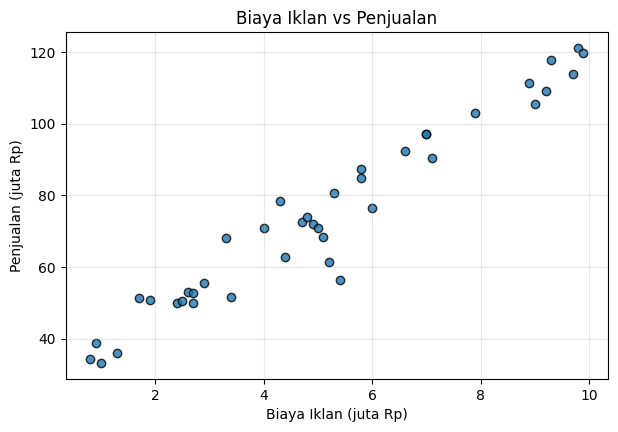

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

X = df_ads[["BiayaIklan"]].values     # double bracket -> 2 dimensi (n, 1)
y = df_ads["Penjualan"].values        # 1 dimensi (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color="tab:blue", edgecolor="k", alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
model_ne = LinearRegression()
model_ne.fit(X_train, y_train)

b = model_ne.intercept_
m = model_ne.coef_[0]
print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan     : y_hat = {b:.4f} + {m:.4f} * X")


Intercept (b) : 29.8900
Koefisien (m) : 8.9707
Persamaan     : y_hat = 29.8900 + 8.9707 * X


**Jawaban A3 (interpretasi):**

Persamaan regresinya adalah $\hat{y} = 29.8900 + 8.9707X$. Koefisien $m = 8.9707$ artinya **setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan per bulan naik rata-rata sekitar 8,97 juta Rp** (dengan asumsi hubungan linear). Intercept $b = 29.8900$ berarti saat biaya iklan 0, model memperkirakan penjualan dasar sekitar 29,89 juta Rp per bulan, yaitu penjualan yang datang dari faktor lain di luar iklan.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = model_ne.predict(X_train)
y_pred_test = model_ne.predict(X_test)

hasil_a4 = pd.DataFrame({
    "MAE":  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    "MSE":  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    "RMSE": [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    "R2":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=["Training", "Testing"])
display(hasil_a4.round(4))
print("Rata-rata Penjualan (y_train):", round(y_train.mean(), 2), "| Std y_train:", round(y_train.std(), 2))


,MAE,MSE,RMSE,R2
Training,4.1355,33.1564,5.7582,0.9447
Testing,6.1503,52.9009,7.2733,0.9315


Rata-rata Penjualan (y_train): 74.63 | Std y_train: 24.48


**Jawaban A4 (analisis):**

| | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| Training | 4.1355 | 33.1564 | 5.7582 | 0.9447 |
| Testing | 6.1503 | 52.9009 | 7.2733 | 0.9315 |

- **RMSE** pada data testing = 7,27, artinya rata-rata prediksi model meleset sekitar 7,3 juta Rp dari penjualan sebenarnya (satuannya sama dengan `Penjualan`). Sebagai pembanding, standar deviasi penjualan pada data training sekitar 24,5 juta Rp, jadi kesalahan model jauh lebih kecil daripada sebaran data aslinya.
- **R²** pada data testing = 0,9315, artinya sekitar 93% variasi penjualan pada data testing bisa dijelaskan oleh biaya iklan. Pada data training R² = 0,9447.
- **Kesimpulan:** model ini sudah **baik**. R² tinggi di kedua data dan selisih antara training (0,9447) dan testing (0,9315) kecil, sehingga tidak ada tanda overfitting dan model bisa digeneralisasi ke data baru. Error testing (RMSE 7,27) sedikit lebih besar daripada training (5,76), yang wajar karena model dilatih pada data training. Perlu diingat data testing hanya 8 titik, jadi angka ini masih mudah bergeser kalau pembagian datanya berbeda.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Model,Learning rate,Intercept,Koefisien,Loss akhir (MSE)
0,Normal Equation,-,29.890031,8.970671,33.156409
1,Gradient Descent,0.001,26.659798,9.478980,35.459123
2,Gradient Descent,0.02,29.890031,8.970671,33.156409
3,Gradient Descent,0.1,NaN,NaN,NaN


/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
<cell>:38: RuntimeWarning: overflow encountered in square
<cell>:39: RuntimeWarning: overflow encountered in matmul
<cell>:39: RuntimeWarning: invalid value encountered in subtract


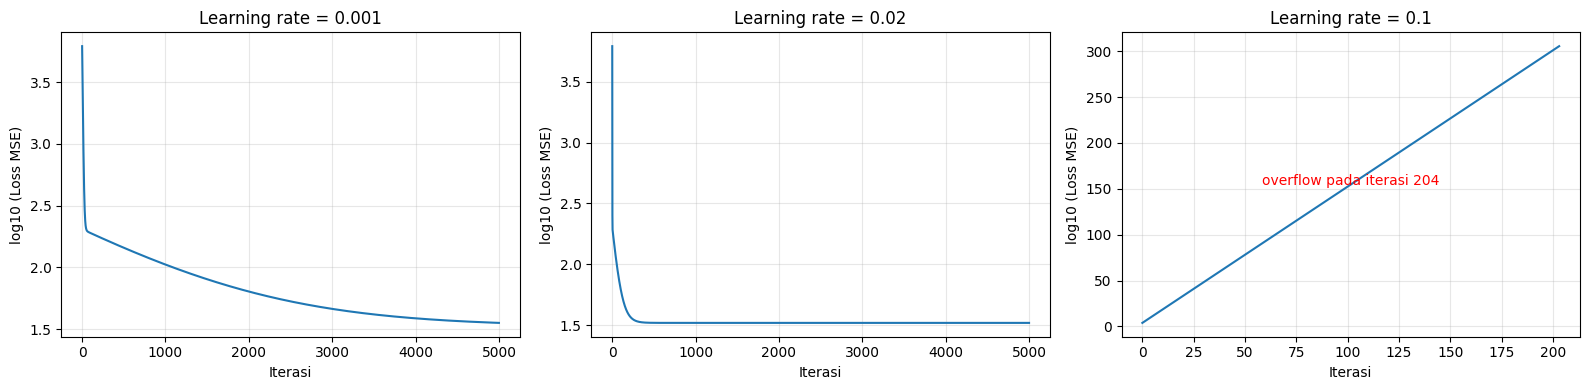

In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
baris = [{"Model": "Normal Equation", "Learning rate": "-", "Intercept": model_ne.intercept_,
          "Koefisien": model_ne.coef_[0], "Loss akhir (MSE)": mse(y_train, model_ne.predict(X_train))}]

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models_gd[lr] = gd
    baris.append({"Model": "Gradient Descent", "Learning rate": lr, "Intercept": gd.intercept_,
                  "Koefisien": gd.coef_[0], "Loss akhir (MSE)": gd.loss_history_[-1]})

display(pd.DataFrame(baris))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(models_gd[lr].loss_history_, dtype=float)
    valid = np.isfinite(loss)                    # iterasi setelah overflow bernilai inf/nan -> tidak digambar
    ax.plot(np.arange(len(loss))[valid], np.log10(loss[valid]))   # log10(loss) = skala log, aman untuk angka sangat besar
    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("log10 (Loss MSE)")
    ax.grid(alpha=0.3)
    if not valid.all():
        ax.annotate(f"overflow pada iterasi {np.argmax(~valid)}", xy=(0.5, 0.5), xycoords="axes fraction", ha="center", color="red")
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**

| Model | Intercept | Koefisien | Loss akhir (MSE) |
|---|---|---|---|
| Normal equation | 29.8900 | 8.9707 | 33.1564 |
| GD, lr = 0.001 | 26.6598 | 9.4790 | 35.4591 |
| GD, lr = 0.02 | 29.8900 | 8.9707 | 33.1564 |
| GD, lr = 0.1 | NaN | NaN | NaN |

- **lr = 0.001 (terlalu lambat):** loss turun sangat pelan. Setelah 5000 iterasi loss masih 35,46, belum sampai ke 33,16, dan parameternya (26,66 dan 9,48) masih berbeda dari normal equation. Langkah per iterasi terlalu kecil, sehingga butuh jauh lebih banyak iterasi untuk sampai ke minimum.
- **lr = 0.02 (pas):** loss turun cepat, sudah hampir mencapai nilai akhirnya sekitar iterasi ke-360 sampai 500, lalu stabil. Intercept dan koefisien akhirnya identik dengan normal equation (29,8900 dan 8,9707). Ini menunjukkan gradient descent dan normal equation mencari solusi yang sama.
- **lr = 0.1 (divergen):** langkah terlalu besar sehingga parameter melompati titik minimum ke sisi seberangnya dan lompatannya makin jauh di tiap iterasi. Loss malah membesar (sekitar 10¹⁸ pada iterasi ke-10) hingga **overflow pada iterasi ke-204**, lalu menjadi `inf`/`NaN`. Karena itu intercept dan koefisien akhirnya `NaN`.
- **Arti `RuntimeWarning: overflow`:** angka sudah melebihi batas terbesar yang bisa disimpan tipe float64 (sekitar 10³⁰⁸). Ini bukan bug kode, melainkan tanda bahwa learning rate terlalu besar untuk data ini (fitur `BiayaIklan` bernilai hingga sekitar 10 dan tidak diskalakan, sehingga gradiennya besar).


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Rentang BiayaIklan pada data training: 0.8 - 9.8 juta
Biaya iklan  4.5 juta -> prediksi penjualan 70.26 juta
Biaya iklan  7.0 juta -> prediksi penjualan 92.68 juta
Biaya iklan 12.0 juta -> prediksi penjualan 137.54 juta  <-- di luar rentang data (ekstrapolasi)


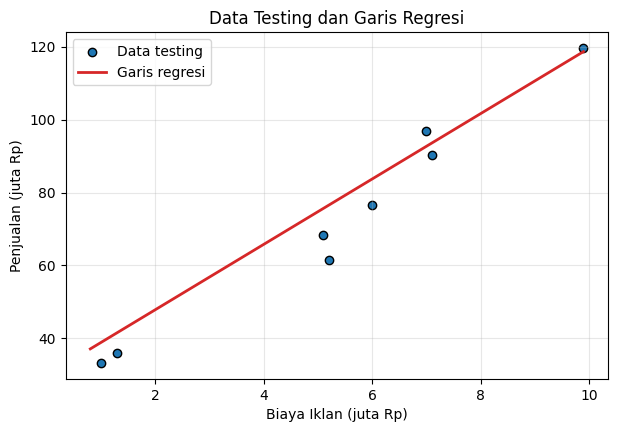

In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (Soal A3)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color="tab:blue", edgecolor="k", label="Data testing")
plt.plot(x_line, model_ne.predict(x_line), color="tab:red", linewidth=2, label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = model_ne.predict(biaya_baru)
print(f"Rentang BiayaIklan pada data training: {X_train.min():.1f} - {X_train.max():.1f} juta")
for xb, pb in zip(biaya_baru[:, 0], pred_baru):
    catatan = "  <-- di luar rentang data (ekstrapolasi)" if xb > X_train.max() else ""
    print(f"Biaya iklan {xb:>4.1f} juta -> prediksi penjualan {pb:.2f} juta{catatan}")


**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta menghasilkan sekitar **70,26 juta**, 7 juta menghasilkan sekitar **92,68 juta**, dan 12 juta menghasilkan sekitar **137,54 juta**.

Prediksi untuk 12 juta adalah **ekstrapolasi**, karena data training hanya berada pada rentang biaya iklan 0,8 sampai 9,8 juta. Menurut saya hasil ini **kurang bisa dipercaya**. Model hanya belajar pola di rentang data yang ada dan tidak ada bukti bahwa hubungannya tetap linear di luar rentang itu. Dalam kenyataan, penjualan bisa mencapai titik jenuh (*diminishing returns*) saat biaya iklan makin besar, misalnya karena pasar sudah terjangkau, sehingga kenaikan penjualan sebenarnya bisa lebih kecil daripada 137,5 juta. Sebaliknya, prediksi untuk 4,5 dan 7 juta (interpolasi, di dalam rentang data) jauh lebih bisa dipercaya.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Bukan Spam (0): 35 email
Spam (1)      : 25 email
Shape X: (60, 2) | Shape y: (60,)


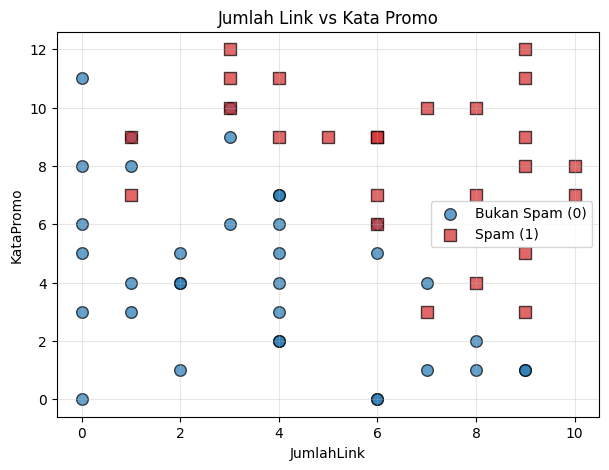

In [9]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())

jumlah = df_email["Spam"].value_counts().sort_index()
print(f"Bukan Spam (0): {jumlah[0]} email")
print(f"Spam (1)      : {jumlah[1]} email")

X_e = df_email[["JumlahLink", "KataPromo"]].values
y_e = df_email["Spam"].values
print("Shape X:", X_e.shape, "| Shape y:", y_e.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_e[y_e == 0, 0], X_e[y_e == 0, 1], c="tab:blue", edgecolor="k", s=70, alpha=0.7, label="Bukan Spam (0)")
plt.scatter(X_e[y_e == 1, 0], X_e[y_e == 1, 1], c="tab:red", marker="s", edgecolor="k", s=70, alpha=0.7, label="Spam (1)")
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Intercept (b)        : -8.6728
Koefisien m1 (Link)  : 0.7786
Koefisien m2 (Promo) : 0.7087
P(Spam) = sigmoid(-8.6728 + 0.7786 * JumlahLink + 0.7087 * KataPromo)
Loss iterasi ke-1    : 0.6931
Loss iterasi ke-1000 : 0.3383
Loss iterasi ke-5000 : 0.3069
Loss iterasi terakhir: 0.3059


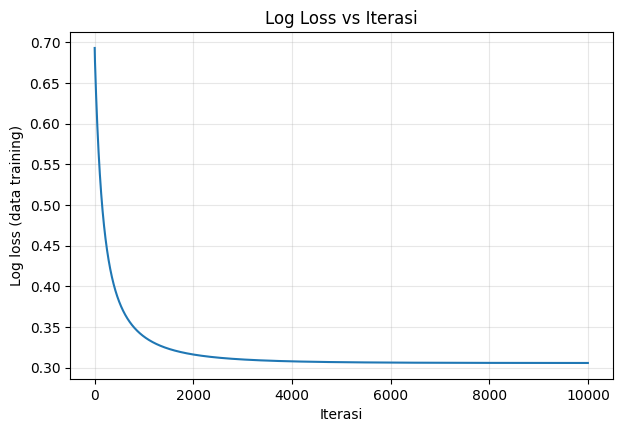

In [10]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_e, y_e, test_size=0.25, random_state=RANDOM_STATE)
print("Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(Xe_train, ye_train)

b0 = log_model.intercept_
m1, m2 = log_model.coef_
print(f"Intercept (b)        : {b0:.4f}")
print(f"Koefisien m1 (Link)  : {m1:.4f}")
print(f"Koefisien m2 (Promo) : {m2:.4f}")
print(f"P(Spam) = sigmoid({b0:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

plt.figure(figsize=(7, 4.5))
plt.plot(log_model.loss_history_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss (data training)")
plt.grid(alpha=0.3)
plt.show()
print("Loss iterasi ke-1    :", round(log_model.loss_history_[0], 4))
print("Loss iterasi ke-1000 :", round(log_model.loss_history_[999], 4))
print("Loss iterasi ke-5000 :", round(log_model.loss_history_[4999], 4))
print("Loss iterasi terakhir:", round(log_model.loss_history_[-1], 4))


**Jawaban B2 (analisis):**

Persamaannya: $P(\text{Spam}) = \sigma(-8.6728 + 0.7786 \cdot \text{JumlahLink} + 0.7087 \cdot \text{KataPromo})$.

Kedua koefisien bernilai positif, artinya makin banyak link dan makin banyak kata promosi, makin besar peluang email dianggap spam. Pengaruh `JumlahLink` (0,7786) sedikit lebih besar daripada `KataPromo` (0,7087), tetapi keduanya sebanding.

Loss sudah **turun dan stabil**: dari 0,6931 pada iterasi pertama (nilai $\ln 2$ karena parameter awal 0 sehingga semua probabilitas 0,5), menjadi 0,3383 pada iterasi ke-1000, 0,3069 pada iterasi ke-5000, dan 0,3059 pada iterasi terakhir. Penurunan di paruh kedua sangat kecil (sekitar 0,001), jadi kurvanya sudah mendatar.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = log_model.predict(Xe_test)          # threshold 0.5
cm = confusion_matrix(ye_test, ye_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Accuracy : {accuracy_score(ye_test, ye_pred):.4f}")
print(f"Precision: {precision_score(ye_test, ye_pred):.4f}")
print(f"Recall   : {recall_score(ye_test, ye_pred):.4f}")
print(f"F1-score : {f1_score(ye_test, ye_pred):.4f}")
print("\nConfusion matrix (data testing):")
display(pd.DataFrame(cm, index=["Aktual Bukan Spam", "Aktual Spam"], columns=["Prediksi Bukan Spam", "Prediksi Spam"]))
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


Accuracy : 0.9333
Precision: 0.8750
Recall   : 1.0000
F1-score : 0.9333

Confusion matrix (data testing):


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,7,1
Aktual Spam,0,7


TN=7, FP=1, FN=0, TP=7


**Jawaban B3 (analisis):**

Hasil pada data testing (15 email, threshold 0,5): accuracy = 0,9333; precision = 0,8750; recall = 1,0; F1 = 0,9333. Confusion matrix: TN = 7, FP = 1, FN = 0, TP = 7.

- **FP (false positive)**: email yang sebenarnya *bukan spam* tetapi diprediksi *spam*. Akibatnya email normal (bahkan mungkin penting) masuk ke folder spam.
- **FN (false negative)**: email yang sebenarnya *spam* tetapi diprediksi *bukan spam*. Akibatnya spam lolos ke inbox.
- Menurut saya **FP lebih merugikan** pengguna per kejadian. Email spam yang lolos hanya mengganggu dan bisa dihapus manual, sedangkan email penting yang salah masuk folder spam (misalnya informasi pekerjaan, kuliah, atau tagihan) bisa tidak terbaca dan menimbulkan kerugian nyata. Karena itu precision patut diperhatikan pada filter spam.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.6728 + 0.7786 * JumlahLink) / 0.7087
                   KataPromo = 12.2374 + -1.0986 * JumlahLink
Jumlah data testing salah klasifikasi: 1 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,6,6,0,1,0.5625


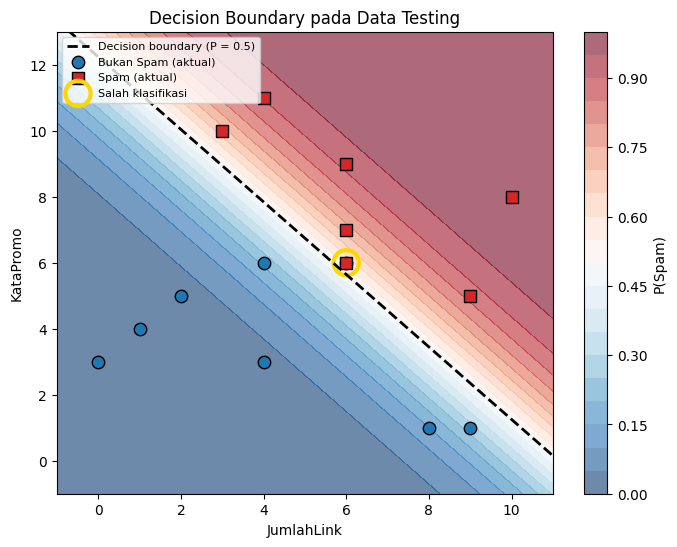

In [12]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: KataPromo = -({b0:.4f} + {m1:.4f} * JumlahLink) / {m2:.4f}")
print(f"                   KataPromo = {-b0 / m2:.4f} + {-m1 / m2:.4f} * JumlahLink")

# 2. Visualisasi data testing + background probabilitas
x1_grid, x2_grid = np.meshgrid(np.linspace(-1, 11, 300), np.linspace(-1, 13, 300))
grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
prob_grid = log_model.predict_proba(grid).reshape(x1_grid.shape)

salah = ye_pred != ye_test                      # 3. penanda data yang salah klasifikasi
plt.figure(figsize=(8, 6))
cs = plt.contourf(x1_grid, x2_grid, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")
x1_line = np.linspace(-1, 11, 100)
plt.plot(x1_line, -(b0 + m1 * x1_line) / m2, "k--", linewidth=2, label="Decision boundary (P = 0.5)")
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], c="tab:blue", edgecolor="k", s=80, label="Bukan Spam (aktual)")
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], c="tab:red", marker="s", edgecolor="k", s=80, label="Spam (aktual)")
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=330, facecolors="none", edgecolors="gold", linewidths=3, label="Salah klasifikasi")
plt.xlim(-1, 11); plt.ylim(-1, 13)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper left", fontsize=8)
plt.show()

print("Jumlah data testing salah klasifikasi:", salah.sum(), "dari", len(ye_test))
if salah.sum() > 0:
    detail = pd.DataFrame(Xe_test[salah], columns=["JumlahLink", "KataPromo"])
    detail["Aktual"] = ye_test[salah]
    detail["Prediksi"] = ye_pred[salah]
    detail["P(Spam)"] = log_model.predict_proba(Xe_test[salah]).round(4)
    display(detail)


**Jawaban B4 (analisis):**

Persamaan decision boundary: $x_2 = -\dfrac{-8.6728 + 0.7786\,x_1}{0.7087} = 12.2374 - 1.0986\,x_1$, yaitu `KataPromo = 12.2374 - 1.0986 * JumlahLink`. Titik di atas garis diprediksi Spam dan titik di bawahnya Bukan Spam.

Dari 15 data testing, **hanya 1 yang salah klasifikasi** (ditandai lingkaran kuning): email dengan `JumlahLink = 6` dan `KataPromo = 6` yang sebenarnya *Bukan Spam* tetapi diprediksi Spam dengan $P(\text{Spam}) = 0.5625$. Titik ini berada sangat dekat dengan garis boundary, tepat di daerah abu-abu tempat probabilitasnya sekitar 0,5, sehingga wajar bila meleset. Itu adalah satu FP yang terlihat di confusion matrix Soal B3.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = log_model.predict_proba(Xe_test)
baris = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba_test >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(ye_test, pred_t).ravel()
    baris.append({"Threshold": t, "TN": tn_, "FP": fp_, "FN": fn_, "TP": tp_,
                  "Accuracy": accuracy_score(ye_test, pred_t),
                  "Precision": precision_score(ye_test, pred_t),
                  "Recall": recall_score(ye_test, pred_t)})
display(pd.DataFrame(baris).round(4))


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall
0,0.3,7,1,0,7,0.9333,0.875,1.0000
1,0.5,7,1,0,7,0.9333,0.875,1.0000
2,0.7,8,0,2,5,0.8667,1.000,0.7143


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall |
|---|---|---|---|---|---|---|---|
| 0.3 | 7 | 1 | 0 | 7 | 0.9333 | 0.8750 | 1.0000 |
| 0.5 | 7 | 1 | 0 | 7 | 0.9333 | 0.8750 | 1.0000 |
| 0.7 | 8 | 0 | 2 | 5 | 0.8667 | 1.0000 | 0.7143 |

**Pengaruh threshold:** menurunkan threshold membuat model lebih mudah memberi label Spam, sehingga lebih banyak spam tertangkap (recall naik atau tetap) tetapi lebih banyak email normal ikut terjaring (FP naik, precision turun). Menaikkan threshold membuat model lebih "pelit" memberi label Spam, sehingga FP berkurang (precision naik) tetapi spam yang lolos bertambah (FN naik, recall turun). Jadi precision dan recall saling tarik-menarik.

Hal ini terlihat pada hasil saya. Dari 0,5 ke 0,7 precision naik dari 0,875 menjadi 1,0 (FP hilang), tetapi recall turun dari 1,0 menjadi 0,7143 (2 spam lolos). Threshold 0,3 tidak mengubah apa pun dibanding 0,5 karena tidak ada email di data testing yang probabilitasnya berada di antara 0,3 dan 0,5 dengan label berbeda dari hasil threshold 0,5.

**Threshold pilihan saya: 0,5.** Walaupun FP lebih merugikan per kejadian (Soal B3), threshold 0,7 menukar 1 FP dengan 2 FN, dan menurunkan accuracy (0,9333 menjadi 0,8667) serta F1 (0,9333 menjadi 0,8333). Pada data ini, threshold 0,5 memberi keseimbangan terbaik: tidak ada spam yang lolos dan hanya 1 email normal yang salah masuk. Jika filter dipakai pada situasi yang sangat sensitif terhadap FP, threshold sedikit di atas 0,5 (misalnya 0,6) bisa dipertimbangkan, tetapi perlu diuji dulu karena data testing hanya 15 email.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.5      # threshold pilihan dari Soal B5 (alasan ada di analisis B5)

email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
p_baru = log_model.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = p_baru.round(4)
email_baru["Kelas"] = np.where(p_baru >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
display(email_baru)


,Email,JumlahLink,KataPromo,P(Spam),Kelas
0,E1,1,2,0.0015,Bukan Spam
1,E2,5,6,0.3711,Bukan Spam
2,E3,9,10,0.9956,Spam
3,E4,2,11,0.6638,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena keluaran akhirnya adalah **kelas** (misalnya Spam atau Bukan Spam), bukan angka kontinu. Kata "regression" ada karena model ini tetap menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$ seperti regresi linear. Fungsi **sigmoid** $\sigma(z) = \frac{1}{1+e^{-z}}$ mengubah $z$ (yang bisa bernilai berapa saja) menjadi angka antara 0 dan 1 yang diartikan sebagai probabilitas kelas positif. Probabilitas itu lalu dibandingkan dengan threshold (default 0,5) untuk menentukan kelas akhirnya.

**Jawaban C2:**

**Normal equation** menghitung parameter langsung dalam sekali hitung memakai rumus aljabar matriks $\theta = (X^TX)^{-1}X^Ty$, tanpa learning rate dan tanpa iterasi. **Gradient descent** mencari parameter secara bertahap: menghitung gradien loss lalu memperbarui parameter sedikit demi sedikit, dan bergantung pada learning rate serta jumlah iterasi. Pada Soal A5 hasil gradient descent dengan lr = 0,02 sama persis dengan normal equation. Gradient descent sebaiknya dipakai saat jumlah fitur atau data sangat besar (membalik matriks mahal dan lambat) atau saat modelnya tidak punya solusi rumus tertutup, seperti Logistic Regression.

**Jawaban C3:**

Evaluasi pada data testing karena tujuan model adalah bekerja baik pada **data baru yang belum pernah dilihat**. Skor pada data training bisa menipu karena model sudah "melihat" data itu. **Overfitting** adalah kondisi saat model terlalu menyesuaikan diri dengan data training (termasuk noise-nya) sehingga skornya sangat bagus di training tetapi jelek di data testing. Pada tugas ini R² training 0,9447 dan R² testing 0,9315 hampir sama, jadi tidak ada tanda overfitting, tetapi tanpa data testing kita tidak bisa memastikan hal itu.

**Jawaban C4:**

Linear Regression memprediksi **angka kontinu**, sehingga cocok memakai MSE yang mengukur jarak kuadrat antara prediksi dan nilai sebenarnya. Logistic Regression menghasilkan **probabilitas** antara 0 dan 1 untuk label 0/1. Jika MSE dipakai dengan sigmoid, fungsi loss menjadi tidak cembung (banyak titik datar) sehingga gradient descent sulit optimal. Log loss $-[y\ln p + (1-y)\ln(1-p)]$ cocok karena memberi hukuman sangat besar jika model yakin tetapi salah (misalnya $p$ mendekati 0 padahal kelas sebenarnya 1), dan loss-nya cembung sehingga mudah dioptimasi.

**Jawaban C5:**

Karena `random_state` berasal dari 2 digit terakhir NIM, sehingga cara data diacak dan dibagi menjadi data training dan data testing berbeda dengan teman. Data training yang berbeda menghasilkan koefisien yang sedikit berbeda, dan data testing yang berbeda menghasilkan akurasi, R², dan metrik lain yang berbeda. Ini terutama terasa karena datasetnya kecil (40 dan 60 baris), sehingga komposisi pembagian data cukup berpengaruh.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("== Linear Regression ==")
display(pd.DataFrame({"Intercept": [model_ne.intercept_, sk_lin.intercept_],
                      "Koefisien": [model_ne.coef_[0], sk_lin.coef_[0]],
                      "R2 test":   [r2_score(y_test, model_ne.predict(X_test)), r2_score(y_test, sk_lin.predict(X_test))],
                      "RMSE test": [rmse(y_test, model_ne.predict(X_test)), rmse(y_test, sk_lin.predict(X_test))]},
                     index=["Implementasi sendiri", "scikit-learn"]).round(6))

# --- Logistic Regression ---
sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                  # C=1.0 (regularisasi L2)
sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)  # hampir tanpa regularisasi

def ringkas(nama, intercept, coef, y_pred):
    return {"Model": nama, "Intercept": intercept, "m1 (Link)": coef[0], "m2 (Promo)": coef[1],
            "Accuracy": accuracy_score(ye_test, y_pred), "Precision": precision_score(ye_test, y_pred),
            "Recall": recall_score(ye_test, y_pred), "F1": f1_score(ye_test, y_pred)}

print("== Logistic Regression ==")
display(pd.DataFrame([
    ringkas("Implementasi sendiri", log_model.intercept_, log_model.coef_, log_model.predict(Xe_test)),
    ringkas("sklearn (default, C=1.0)", sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas("sklearn (C=1e10, tanpa regularisasi)", sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xe_test)),
]).round(4))


== Linear Regression ==


,Intercept,Koefisien,R2 test,RMSE test
Implementasi sendiri,29.890031,8.970671,0.931499,7.273297
scikit-learn,29.890031,8.970671,0.931499,7.273297


== Logistic Regression ==


,Model,Intercept,m1 (Link),m2 (Promo),Accuracy,Precision,Recall,F1
0,Implementasi sendiri,-8.6728,0.7786,0.7087,0.9333,0.875,1.0,0.9333
1,"sklearn (default, C=1.0)",-8.0475,0.7166,0.6573,0.9333,0.875,1.0,0.9333
2,"sklearn (C=1e10, tanpa regularisasi)",-8.8420,0.7942,0.7225,0.9333,0.875,1.0,0.9333


**Jawaban Bonus (analisis):**

**Linear Regression:** hasil scikit-learn **identik** dengan implementasi saya (intercept 29.8900, koefisien 8.9707, R² testing 0.9315). Ini wajar karena keduanya sama-sama menyelesaikan solusi kuadrat terkecil (*ordinary least squares*) dengan rumus langsung, dan tidak memakai regularisasi.

**Logistic Regression:** koefisiennya **berbeda**.

| Model | Intercept | m1 (Link) | m2 (Promo) |
|---|---|---|---|
| Implementasi sendiri | -8.6728 | 0.7786 | 0.7087 |
| sklearn default (C = 1.0) | -8.0475 | 0.7166 | 0.6573 |
| sklearn C = 1e10 | -8.8420 | 0.7942 | 0.7225 |

Penyebab utama: `LogisticRegression` di scikit-learn secara default memakai **regularisasi L2** (`penalty='l2'`, `C=1.0`) yang menambahkan hukuman pada besarnya koefisien, sehingga koefisiennya lebih kecil. Jika regularisasi hampir dimatikan (`C=1e10`), koefisien sklearn (0.7942 dan 0.7225) menjadi mendekati hasil saya. Hasil saya masih sedikit lebih kecil daripada versi tanpa regularisasi karena data hampir terpisah sempurna, sehingga bobot optimal terus membesar, sedangkan gradient descent saya berhenti pada 10.000 iterasi (dan pada saat itu loss masih turun pelan). Walaupun koefisiennya berbeda, **metrik evaluasi pada data testing sama** (F1 = 0.9333), jadi kualitas prediksinya setara.
